# Decision Tree Regression: scikit-learn vs Moxie

**Reference example:** `../scikit-learn/examples/tree/plot_tree_regression.py` at scikit-learn
`4358542a1bd39af2e7e1cbace8b9fed067473c5b`
([rendered gallery page](https://scikit-learn.org/dev/auto_examples/tree/plot_tree_regression.html)).

**Scenario:** `DecisionTreeRegressor(max_depth=2|5)` on a noisy 1-D sine, then multi-output
`DecisionTreeRegressor(max_depth=2|5|8)` predicting `(pi sin x, pi cos x)`, evaluated on dense
grids (500 and 20,000 points). Extra checks: thresholds, leaf counts, `score` (R2) on the training
data and `apply` on the grid.

**Adaptations:**
- Synthetic data generated exactly as in the example (`RandomState(1)`), shared as Float32 features
  (sklearn's internal dtype) and Float64 targets.
- The example leaves `random_state=None`. With a single feature and `max_features=None`, the feature
  permutation is the only random step and cannot change the tree, so both sides are deterministic.
  Moxie draws from its entropy source for `None`, exactly like sklearn draws from NumPy's global state.
- The Python cells use the scikit-learn wheel installed in the notebooks environment.

**Determinism:** deterministic (see above).

In [1]:
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "notebooks/_support/moxie_nb.py").exists())
sys.path.insert(0, str(ROOT / "notebooks/_support"))
%load_ext moxie_nb
nb = moxie_nb.Session("tree/plot_tree_regression")

## 1. scikit-learn (Python reference)

The official example code with smaller figures.

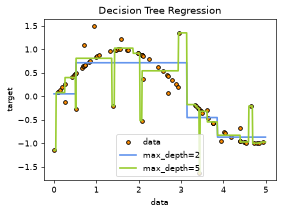

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor

plt.rcParams["figure.dpi"] = 60

# Create a random 1D dataset
rng = np.random.RandomState(1)
X = np.sort(5 * rng.rand(80, 1), axis=0)
y = np.sin(X).ravel()
y[::5] += 3 * (0.5 - rng.rand(16))

regr_1 = DecisionTreeRegressor(max_depth=2)
regr_2 = DecisionTreeRegressor(max_depth=5)
regr_1.fit(X, y)
regr_2.fit(X, y)

X_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
y_1 = regr_1.predict(X_test)
y_2 = regr_2.predict(X_test)

plt.figure(figsize=(5, 3.5))
plt.scatter(X, y, s=20, edgecolor="black", c="darkorange", label="data")
plt.plot(X_test, y_1, color="cornflowerblue", label="max_depth=2", linewidth=2)
plt.plot(X_test, y_2, color="yellowgreen", label="max_depth=5", linewidth=2)
plt.xlabel("data")
plt.ylabel("target")
plt.title("Decision Tree Regression")
plt.legend()
plt.show()

sk1 = dict(pred=[y_1, y_2], thr=[r.tree_.threshold for r in (regr_1, regr_2)],
           leaves=[r.get_n_leaves() for r in (regr_1, regr_2)],
           r2=[r.score(X, y) for r in (regr_1, regr_2)], apply=[r.apply(X_test) for r in (regr_1, regr_2)])
nb.share(X1=X.astype(np.float32), y1=y, X1_test=X_test.astype(np.float32))

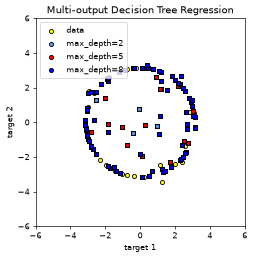

In [3]:
# Multi-output regression
rng = np.random.RandomState(1)
X = np.sort(200 * rng.rand(100, 1) - 100, axis=0)
y = np.array([np.pi * np.sin(X).ravel(), np.pi * np.cos(X).ravel()]).T
y[::5, :] += 0.5 - rng.rand(20, 2)

regr_1 = DecisionTreeRegressor(max_depth=2)
regr_2 = DecisionTreeRegressor(max_depth=5)
regr_3 = DecisionTreeRegressor(max_depth=8)
regr_1.fit(X, y)
regr_2.fit(X, y)
regr_3.fit(X, y)

X_test = np.arange(-100.0, 100.0, 0.01)[:, np.newaxis]
y_1 = regr_1.predict(X_test)
y_2 = regr_2.predict(X_test)
y_3 = regr_3.predict(X_test)

plt.figure(figsize=(4.5, 4.5))
s = 25
plt.scatter(y[:, 0], y[:, 1], c="yellow", s=s, edgecolor="black", label="data")
plt.scatter(y_1[:, 0], y_1[:, 1], c="cornflowerblue", s=s, edgecolor="black", label="max_depth=2")
plt.scatter(y_2[:, 0], y_2[:, 1], c="red", s=s, edgecolor="black", label="max_depth=5")
plt.scatter(y_3[:, 0], y_3[:, 1], c="blue", s=s, edgecolor="black", label="max_depth=8")
plt.xlim([-6, 6])
plt.ylim([-6, 6])
plt.xlabel("target 1")
plt.ylabel("target 2")
plt.title("Multi-output Decision Tree Regression")
plt.legend(loc="best")
plt.show()

sk2 = dict(pred=[y_1, y_2, y_3], thr=[r.tree_.threshold for r in (regr_1, regr_2, regr_3)],
           leaves=[r.get_n_leaves() for r in (regr_1, regr_2, regr_3)],
           r2=[r.score(X, y) for r in (regr_1, regr_2, regr_3)])
nb.share(X2=X.astype(np.float32), y2=y, X2_test=X_test.astype(np.float32))

## 2. Moxie (native Mojo)

In [4]:
%%mojo regression
from moxie.tree import DecisionTreeRegressor
from moxie_nb_io import load, save, save_ints, save_floats


def thresholds(model: DecisionTreeRegressor) raises -> List[Float64]:
    var out = List[Float64]()
    for node in model.tree_.nodes:
        # sklearn's TREE_UNDEFINED (-2.0) on leaves.
        out.append(node.threshold if node.left_child != -1 else -2.0)
    return out^


def main() raises:
    var X1 = load[DType.float32]("X1")
    var y1 = load("y1")
    var X1_test = load[DType.float32]("X1_test")
    var leaves = List[Int]()
    var r2 = List[Float64]()
    var depths: List[Int] = [2, 5]
    for k in range(2):
        var regr = DecisionTreeRegressor(max_depth=depths[k])
        _ = regr.fit(X1, y1)
        save("pred1_" + String(k), regr.predict(X1_test))
        save("apply1_" + String(k), regr.apply(X1_test))
        save_floats("thr1_" + String(k), thresholds(regr))
        leaves.append(regr.get_n_leaves())
        r2.append(regr.score(X1, y1))
    save_ints("leaves1", leaves)
    save_floats("r2_1", r2)

    var X2 = load[DType.float32]("X2")
    var y2 = load("y2")
    var X2_test = load[DType.float32]("X2_test")
    var leaves2 = List[Int]()
    var r2_2 = List[Float64]()
    var depths2: List[Int] = [2, 5, 8]
    for k in range(3):
        var regr = DecisionTreeRegressor(max_depth=depths2[k])
        _ = regr.fit(X2, y2)
        save("pred2_" + String(k), regr.predict(X2_test))
        save_floats("thr2_" + String(k), thresholds(regr))
        leaves2.append(regr.get_n_leaves())
        r2_2.append(regr.score(X2, y2))
    save_ints("leaves2", leaves2)
    save_floats("r2_2", r2_2)
    print("fitted 2 single-output and 3 multi-output regressors")

fitted 2 single-output and 3 multi-output regressors


## 3. Side by side and parity

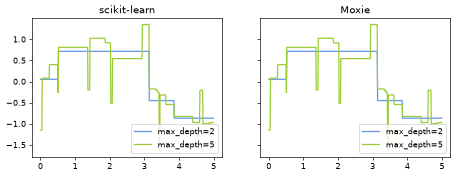

True

In [5]:
mx = nb.results["regression"]
X1_test = np.arange(0.0, 5.0, 0.01)[:, np.newaxis]
fig, axes = plt.subplots(1, 2, figsize=(9, 3), sharey=True)
for ax, label, preds in [(axes[0], "scikit-learn", sk1["pred"]),
                         (axes[1], "Moxie", [mx["pred1_0"], mx["pred1_1"]])]:
    ax.plot(X1_test, preds[0], color="cornflowerblue", label="max_depth=2")
    ax.plot(X1_test, preds[1], color="yellowgreen", label="max_depth=5")
    ax.set_title(label)
    ax.legend()
plt.show()

MEAN = ("leaf means are Float64 weighted sums divided by weights; split search uses the same "
        "proxy-improvement order, so values agree to summation roundoff (family oracle bound 2e-12)")
for k, d in enumerate([2, 5]):
    nb.compare(f"1-D max_depth={d}: predict(X_test)", sk1["pred"][k], mx[f"pred1_{k}"], rtol=2e-12, atol=2e-12, reason=MEAN)
    nb.compare(f"1-D max_depth={d}: tree_.threshold", sk1["thr"][k], mx[f"thr1_{k}"], exact=True)
    nb.compare(f"1-D max_depth={d}: apply(X_test)", sk1["apply"][k], mx[f"apply1_{k}"], exact=True)
nb.compare("1-D get_n_leaves", sk1["leaves"], mx["leaves1"], exact=True)
nb.compare("1-D score (R2)", sk1["r2"], mx["r2_1"], rtol=1e-12, atol=1e-12,
           reason="R2 from Float64 residual sums over identical predictions")
for k, d in enumerate([2, 5, 8]):
    nb.compare(f"multi-output max_depth={d}: predict(X_test)", sk2["pred"][k], mx[f"pred2_{k}"], rtol=2e-12, atol=2e-12, reason=MEAN)
    nb.compare(f"multi-output max_depth={d}: tree_.threshold", sk2["thr"][k], mx[f"thr2_{k}"], exact=True)
nb.compare("multi-output get_n_leaves", sk2["leaves"], mx["leaves2"], exact=True)
nb.compare("multi-output score (uniform R2)", sk2["r2"], mx["r2_2"], rtol=1e-12, atol=1e-12,
           reason="R2 from Float64 residual sums over identical predictions")

In [6]:
nb.report()
nb.assert_parity()

check,status,sklearn shape,moxie shape,max |diff|,max rel,tolerance,detail,tolerance reason
1-D max_depth=2: predict(X_test),PASS,"(500,)","(500,)",0,0,"rtol=2e-12, atol=2e-12",,"leaf means are Float64 weighted sums divided by weights; split search uses the same proxy-improvement order, so values agree to summation roundoff (family oracle bound 2e-12)"
1-D max_depth=2: tree_.threshold,PASS,"(7,)","(7,)",,,exact,0 mismatches,
1-D max_depth=2: apply(X_test),PASS,"(500,)","(500,)",,,exact,0 mismatches,
1-D max_depth=5: predict(X_test),PASS,"(500,)","(500,)",0,0,"rtol=2e-12, atol=2e-12",,"leaf means are Float64 weighted sums divided by weights; split search uses the same proxy-improvement order, so values agree to summation roundoff (family oracle bound 2e-12)"
1-D max_depth=5: tree_.threshold,PASS,"(47,)","(47,)",,,exact,0 mismatches,
1-D max_depth=5: apply(X_test),PASS,"(500,)","(500,)",,,exact,0 mismatches,
1-D get_n_leaves,PASS,"(2,)","(2,)",,,exact,0 mismatches,
1-D score (R2),PASS,"(2,)","(2,)",2.22e-16,2.91e-16,"rtol=1e-12, atol=1e-12",,R2 from Float64 residual sums over identical predictions
multi-output max_depth=2: predict(X_test),PASS,"(20000, 2)","(20000, 2)",0,0,"rtol=2e-12, atol=2e-12",,"leaf means are Float64 weighted sums divided by weights; split search uses the same proxy-improvement order, so values agree to summation roundoff (family oracle bound 2e-12)"
multi-output max_depth=2: tree_.threshold,PASS,"(7,)","(7,)",,,exact,0 mismatches,
